# <center>👁️ Практика 7. Компьютерное зрение и OpenCV</center>
### <center>Прикладные технологии ИИ · 90 минут · Модуль 4</center>

<div style='text-align: center; margin: 20px;'>
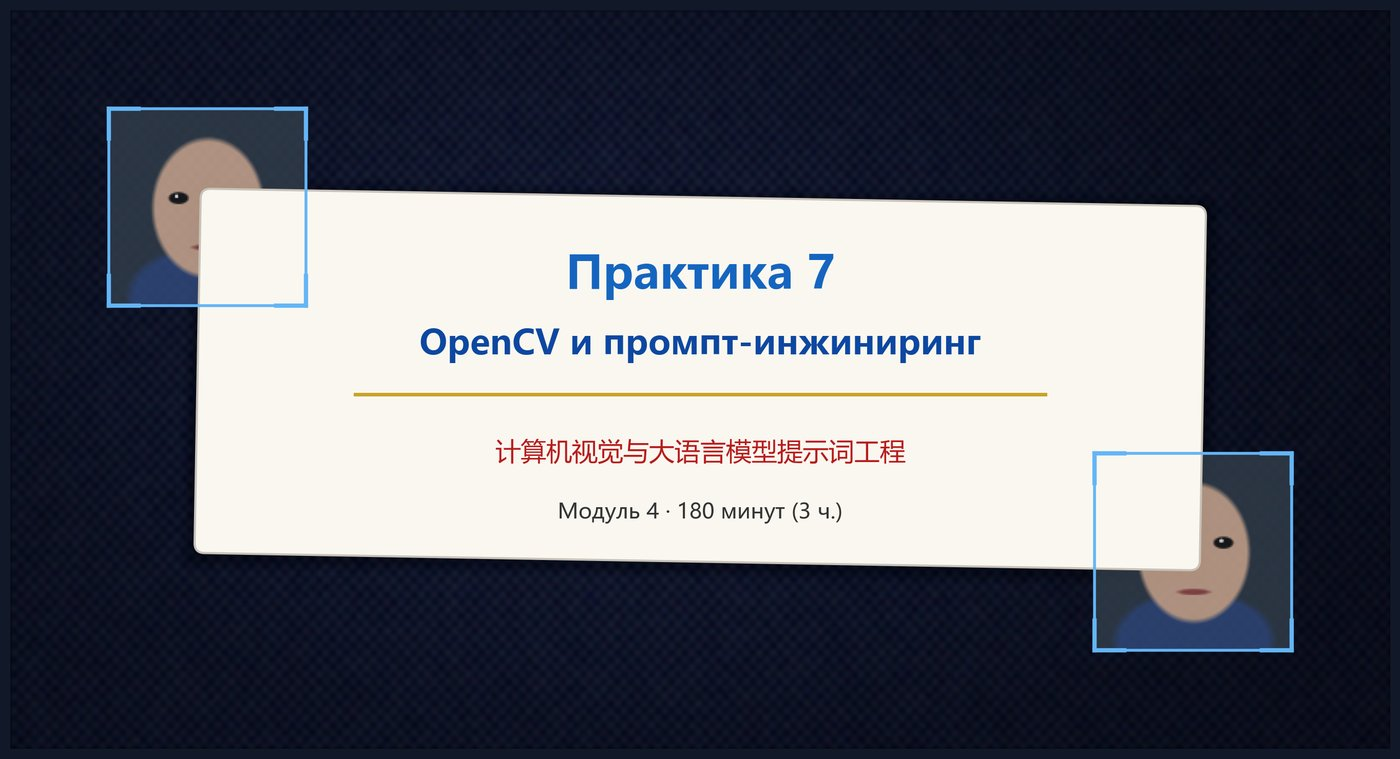
</div>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цель:</b> освоить базовый конвейер обработки изображений в OpenCV — от загрузки и фильтрации до детекции границ, контуров и лиц, — и научиться считать объекты на кадре классическими методами.
</div>

<center><i>Студент: _______________ · Группа: _______________ · Дата: _______________</i></center>


In [1]:
# === Установка OpenCV 4.x (5.0 сломал API — CascadeClassifier недоступен) ===
import sys

# Удаляем 5.0 и все старые варианты
!{sys.executable} -m pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python

# Ставим последнюю стабильную 4.x (проверено — CascadeClassifier работает)
!{sys.executable} -m pip install "opencv-contrib-python<5"

# Если в Китае — раскомментируйте зеркало:
# !{sys.executable} -m pip install "opencv-contrib-python<5" -i https://pypi.tuna.tsinghua.edu.cn/simple

Found existing installation: opencv-contrib-python 4.10.0.84
Uninstalling opencv-contrib-python-4.10.0.84:
  Successfully uninstalled opencv-contrib-python-4.10.0.84


Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
  Using cached opencv_contrib_python-4.14.0.94-cp37-abi3-win_amd64.whl (47.4 MB)


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import base64

# Шрифт для подписей на графиках (русский + латиница)
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

print('✅ OpenCV версии:', cv2.__version__)
print('✅ numpy:', np.__version__)
print('   Путь к cv2:', cv2.__file__)
print()

# === КРИТИЧЕСКАЯ ПРОВЕРКА: доступность CascadeClassifier ===
if not hasattr(cv2, 'CascadeClassifier'):
    print('❌ ОШИБКА: cv2.CascadeClassifier не найден!')
    print()
    print('   Это значит, что загружен НЕ opencv-contrib-python,')
    print('   а opencv-python-headless или старая версия.')
    print()
    print('   Решение:')
    print('   1) Kernel → Restart (перезапустите ядро)')
    print('      После перезапуска выполните ячейки заново.')
    print('   2) Если не помогает — в терминале выполните:')
    print('      pip uninstall opencv-python opencv-python-headless opencv-contrib-python -y')
    print('      pip install opencv-contrib-python')
    print('   3) Затем снова запустите Jupyter и откройте этот ноутбук.')
    print()
    print('   Проверка пути cv2 выше покажет, какой именно модуль загружен.')
    print('   Путь должен содержать site-packages/opencv_contrib_python —')
    print('   если там site-packages/opencv_python_headless — это и есть проблема.')
    raise ImportError('cv2.CascadeClassifier не найден — перезапустите ядро после установки opencv-contrib-python')

print('✅ cv2.CascadeClassifier доступен — можно работать с Haar Cascade')
print('✅ cv2.data.haarcascades:', cv2.data.haarcascades)

# Проверяем, что XML-файл каскада существует
import os
cascade_file = os.path.join(cv2.data.haarcascades, 'haarcascade_frontalface_default.xml')
if os.path.exists(cascade_file):
    print('✅ haarcascade_frontalface_default.xml найден')
else:
    print('⚠️ XML-файл каскада не найден по пути:', cascade_file)
    print('   Возможно, opencv-contrib-python установлен некорректно.')


✅ OpenCV версии: 4.14.0
✅ numpy: 2.2.5
   Путь к cv2: C:\Work\ai_course\env_ai\lib\site-packages\cv2\__init__.py

✅ cv2.CascadeClassifier доступен — можно работать с Haar Cascade
✅ cv2.data.haarcascades: C:\Work\ai_course\env_ai\lib\site-packages\cv2\data\
✅ haarcascade_frontalface_default.xml найден


---
# 📦 Подготовка

## Установка OpenCV

Для этой практики нужен **opencv-contrib-python** (полная сборка с модулем `objdetect`, в котором лежат `cv2.CascadeClassifier` и XML-файлы каскадов).

**Если у вас уже установлен `opencv-python` или `opencv-python-headless`** — их обязательно нужно удалить, иначе возникнет конфликт, и `cv2.CascadeClassifier` будет недоступен.

### Способ 1 (через ячейку выше — рекомендуется)

Ячейка 1 уже выполняет правильную установку: сначала удаляет все старые варианты, затем ставит opencv-contrib-python. **После установки обязательно перезапустите ядро** (Kernel → Restart), чтобы новая версия cv2 загрузилась вместо старой.

### Способ 2 (через терминал, если ячейка не помогает)

Откройте терминал (Anaconda Prompt на Windows) и выполните:

```bash
pip uninstall opencv-python opencv-python-headless opencv-contrib-python -y
pip install opencv-contrib-python
```

Для пользователей в Китае (через зеркало Цинхуа):

```bash
pip uninstall opencv-python opencv-python-headless opencv-contrib-python -y
pip install opencv-contrib-python -i https://pypi.tuna.tsinghua.edu.cn/simple
```

После установки **перезапустите Jupyter** и откройте этот ноутбук снова.

## Фотографии

Все фотографии уже встроены в код как base64 — папка `images/` вам не нужна. Если хотите поэкспиментировать со своими снимками, замените переменные `_B64_REAL_PHOTO_PORTRAIT` / `_B64_REAL_PHOTO_FRIENDS` на свои.

Используйте фотографии людей только с их согласия или общедоступные учебные снимки.


---
# 🌅 Введение в компьютерное зрение

**Компьютерное зрение (Computer Vision, CV)** — это область искусственного интеллекта, в которой алгоритмы «учатся видеть»: получать информацию из цифровых изображений и видео. Если машинное обучение на таблицах работает с признаками, которые подготовил человек, то CV начинает «сырые» пиксели и пытается восстановить смысл: где лицо, какой это объект, есть ли дефект на детали, кто перешёл дорогу.

**Немного истории.** Задача «понять, что на картинке» стоит с 1960-х: тогда исследователи MIT пытались описать сцену через блоки-примитивы, а в 1970-х Дэвид Марр предложил знаменитую теорию — от эскиза нулевого уровня (градиенты) до трёхмерных моделей. К 1990-м появились надёжные детекторы признаков: Harris corners (1988), SIFT (1999), SURF, HOG (2005). В 2001 году Виола и Джонс опубликовали метод **Haar Cascade** для поиска лиц в реальном времени на веб-камере — это была революция скорости (интегральные изображения + каскад AdaBoost). В 2012 году победа AlexNet в конкурсе ImageNet открыла эпоху глубокого обучения: CNN стали стандартом для классификации, детекции и сегментации. Современные модели — YOLO, Faster R-CNN, MTCNN, Segment Anything — показывают точность, недоступную классике, но требуют GPU и больших датасетов.

**Почему OpenCV?** Библиотека OpenCV (Open Computer Vision) вышла в 1999 году из Intel и к сегодняшнему дню содержит более 2500 алгоритмов: от фильтрации и геометрии до нейросетевого модуля DNN. Она **открытая** (BSD-лицензия), **кросс-платформенная** (Windows, Linux, macOS, Android, iOS) и **быстрая** (ядро на C++, привязки к Python, Java, C++). Поддерживает камеры, видеопотоки, стерео-зрение, AR-маркеры. Поэтому OpenCV — это стандарт де-факто и в университетах, и в проде.

**Где применяется CV:** медицина (анализ рентгена, МРТ, поиск патологий), беспилотные автомобили (полосы, пешеходы, знаки), безопасность (распознавание лиц, подсчёт посетителей), промышленность (контроль брака на конвейере), AR/VR (трекинг маркеров и рук), сельское хозяйство (диагностика болезней растений по листу), ритейл (автокассы без штрих-кодов).

**Что мы сделаем в этой практике.** Мы пройдём весь классический конвейер OpenCV: загрузка → цветовые пространства → геометрия → фильтрация → морфология → детекция границ Canny → контуры → Haar Cascade для лиц → подсчёт объектов через HoughCircles. Никаких нейросетей здесь не будет — это тема отдельной практики; цель — научиться чувствовать, что делает каждый фильтр и почему.


---
# 👁️ Часть А. Компьютерное зрение, OpenCV

<div style='text-align: center; margin: 20px;'>
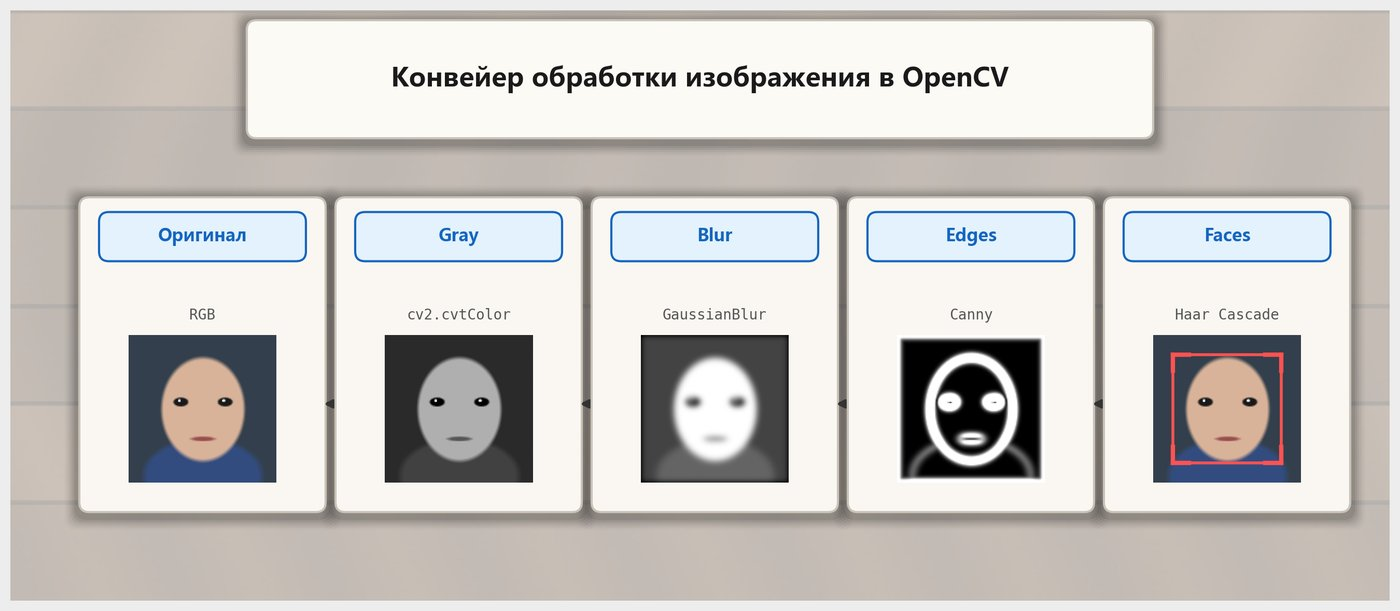
</div>

Типичный конвейер обработки: **сырые пиксели → предобработка (фильтр/цвет/геометрия) → выделение признаков (границы/контуры) → распознавание (классификатор)**. Каждый блок ниже — это отдельный инструмент из этого конвейера.


🖼️ Портрет:  shape=(959, 640, 3), dtype=uint8
👥 Друзья:   shape=(360, 640, 3),  dtype=uint8


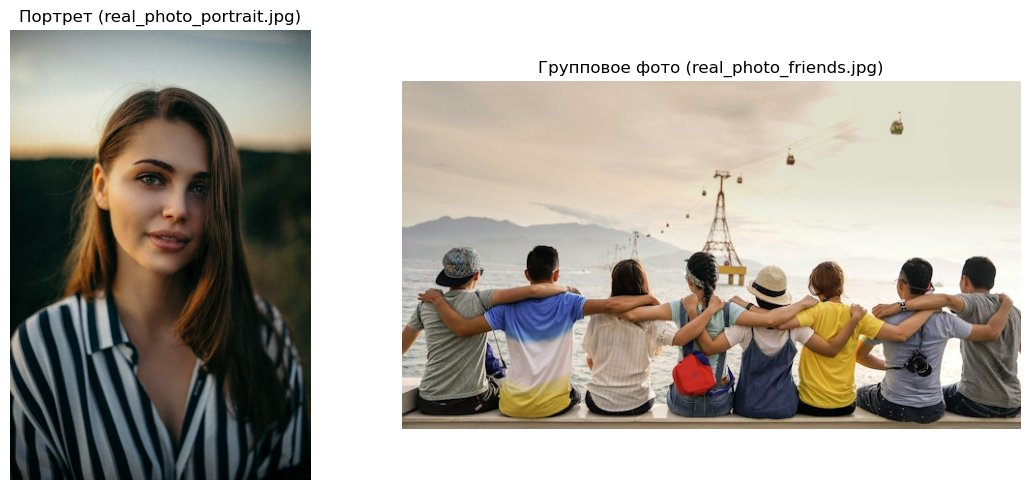

In [3]:
# ============================================================
# Встроенные фотографии (base64). Меняйте на свои, если нужно.
# ============================================================
_B64_REAL_PHOTO_PORTRAIT = """..."""
_B64_REAL_PHOTO_FRIENDS  = """..."""


def load_image_from_b64(b64_str: str) -> np.ndarray:
    """Декодирует base64-JPG в массив OpenCV (BGR)."""
    raw = base64.b64decode(b64_str)
    arr = np.frombuffer(raw, dtype=np.uint8)
    img = cv2.imdecode(arr, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("Не удалось декодировать изображение из base64")
    return img


# Загружаем портрет и групповое фото
img_portrait = load_image_from_b64(_B64_REAL_PHOTO_PORTRAIT)
img_friends  = load_image_from_b64(_B64_REAL_PHOTO_FRIENDS)

print(f"🖼️ Портрет:  shape={img_portrait.shape}, dtype={img_portrait.dtype}")
print(f"👥 Друзья:   shape={img_friends.shape},  dtype={img_friends.dtype}")

# Быстрый предпросмотр (matplotlib ждёт RGB, OpenCV хранит BGR — конвертируем)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(cv2.cvtColor(img_portrait, cv2.COLOR_BGR2RGB))
ax[0].set_title("Портрет (real_photo_portrait.jpg)")
ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(img_friends, cv2.COLOR_BGR2RGB))
ax[1].set_title("Групповое фото (real_photo_friends.jpg)")
ax[1].axis("off")
plt.tight_layout()
plt.show()


---
## 🎨 Цветовые пространства

Пиксель в изображении — это вектор чисел. То, **какие числа** стоят в этом векторе, зависит от цветового пространства. OpenCV умеет работать с десятком пространств через `cv2.cvtColor(img, cv2.COLOR_*)`.

**BGR vs RGB.** Исторически OpenCV формировался под камеры, выдающие данные в порядке Blue-Green-Red. Поэтому по умолчанию `cv2.imread` возвращает **BGR**. Это ловушка для новичка: `matplotlib.pyplot.imshow` ждёт RGB, и если отдать BGR напрямую, красный и синий каналы поменяются местами (лица станут синевато-зелёными). Поэтому перед показом через `plt.imshow` всегда делайте `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`.

**GRAY** — одноканальное пространство яркости (0..255). Серое изображение нужно почти всем детекторам: границы, контуры, Haar Cascade, Hough — все работают с одним каналом, потому что цвет для геометрии не важен, важен перепад яркости.

**HSV** (Hue-Saturation-Value) — цилиндрическое пространство, где тон (H) отделён от насыщенности (S) и яркости (V). Удобно для задач «найти все зелёные объекты» или «оттенить кожу» — достаточно отфильтровать диапазон H, не зависящий от освещения. В OpenCV H ∈ [0, 179] (8-бит), S,V ∈ [0, 255].

**LAB** — перцептивно однородное пространство: L — светлота, A — зелёно-красная ось, B — сине-жёлтая ось. Используется в цветокоррекции и сравнении цветов, потому что одинаковое евклидово расстояние в LAB ≈ одинаково воспринимаемая разница.


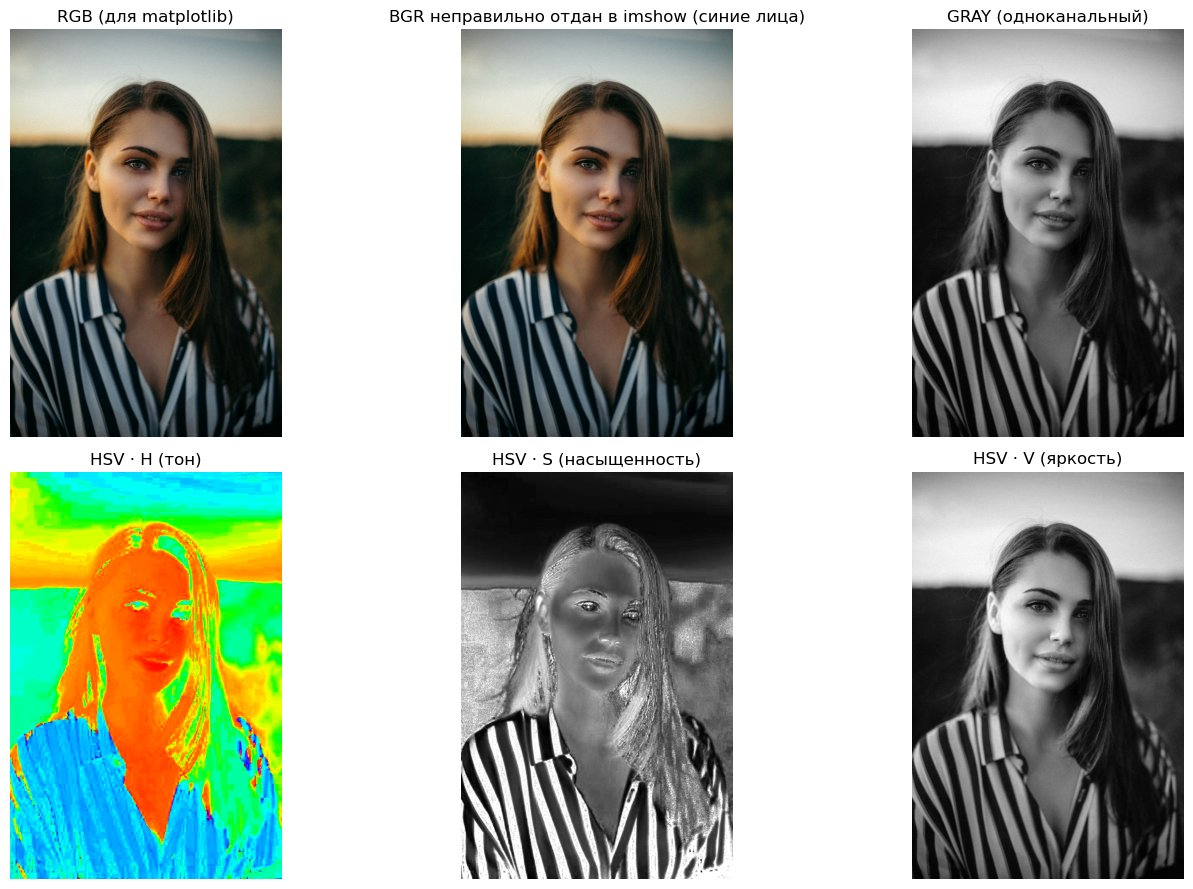

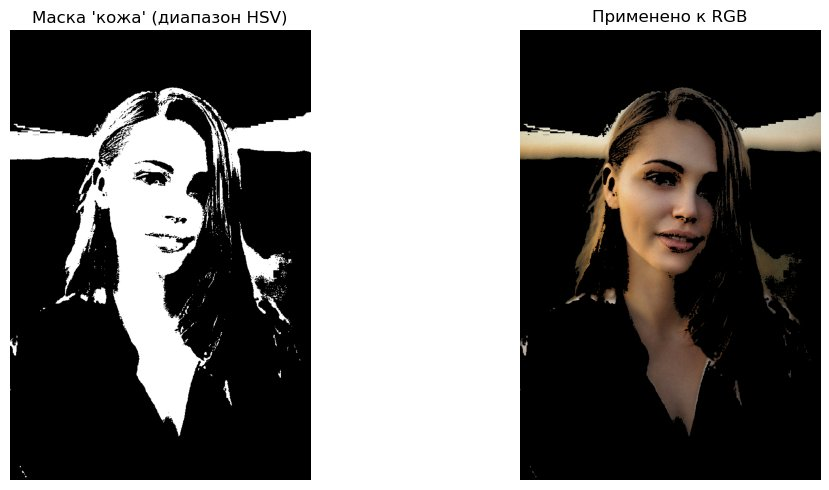

In [4]:
# Сравниваем 4 цветовых представления для портрета
img_rgb   = cv2.cvtColor(img_portrait, cv2.COLOR_BGR2RGB)
img_gray  = cv2.cvtColor(img_portrait, cv2.COLOR_BGR2GRAY)
img_hsv   = cv2.cvtColor(img_portrait, cv2.COLOR_BGR2HSV)
img_lab   = cv2.cvtColor(img_portrait, cv2.COLOR_BGR2LAB)

fig, ax = plt.subplots(2, 3, figsize=(15, 9))

ax[0, 0].imshow(img_rgb)
ax[0, 0].set_title("RGB (для matplotlib)")
ax[0, 1].imshow(cv2.cvtColor(img_portrait, cv2.COLOR_BGR2RGB))  # специально "неправильно" покажем BGR
ax[0, 1].set_title("BGR неправильно отдан в imshow (синие лица)")
ax[0, 2].imshow(img_gray, cmap='gray')
ax[0, 2].set_title("GRAY (одноканальный)")

# HSV — каждый канал отдельно
ax[1, 0].imshow(img_hsv[:, :, 0], cmap='hsv')
ax[1, 0].set_title("HSV · H (тон)")
ax[1, 1].imshow(img_hsv[:, :, 1], cmap='gray')
ax[1, 1].set_title("HSV · S (насыщенность)")
ax[1, 2].imshow(img_hsv[:, :, 2], cmap='gray')
ax[1, 2].set_title("HSV · V (яркость)")

for a in ax.flat:
    a.axis('off')
plt.tight_layout()
plt.show()

# Пример: выделить «кожу» через диапазон HSV
lower_skin = np.array([0, 30, 60], dtype=np.uint8)
upper_skin = np.array([25, 170, 255], dtype=np.uint8)
mask_skin = cv2.inRange(img_hsv, lower_skin, upper_skin)
skin_only = cv2.bitwise_and(img_rgb, img_rgb, mask=mask_skin)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(mask_skin, cmap='gray')
ax[0].set_title("Маска 'кожа' (диапазон HSV)")
ax[1].imshow(skin_only)
ax[1].set_title("Применено к RGB")
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()


---
## 📐 Геометрические преобразования

Изображение в OpenCV — это `np.ndarray` формы `(H, W, C)`. Индекс `[y, x]` — строка, столбец (не наоборот!). Это даёт три быстрых способа изменить геометрию:

- **`cv2.resize(img, (W, H))`** — масштабирование. Можно через `fx=, fy=` (масштабы) или через `interpolation=`: `INTER_NEAREST` (быстро, ступенчато), `INTER_LINEAR` (по умолчанию), `INTER_CUBIC`, `INTER_AREA` (лучше для уменьшения).
- **`cv2.flip(img, flipCode)`** — зеркальное отражение: `0` по горизонтали (по Y), `1` по вертикали (по X), `-1` по обеим.
- **`cv2.warpAffine(img, M, (W, H))`** — любое аффинное преобразование по матрице 2×3. В частности, поворот получается через `cv2.getRotationMatrix2D(center, angle, scale)`.
- **Crop** — просто срез NumPy: `img[y0:y1, x0:x1]`. Бесплатно и мгновенно.

Эти операции — фундамент **аугментации датасета**: для обучения нейросети часто генерируют десятки вариантов одного снимка (поворот ±15°, отражение, случайный crop), чтобы модель стала инвариантна к этим искажениям.


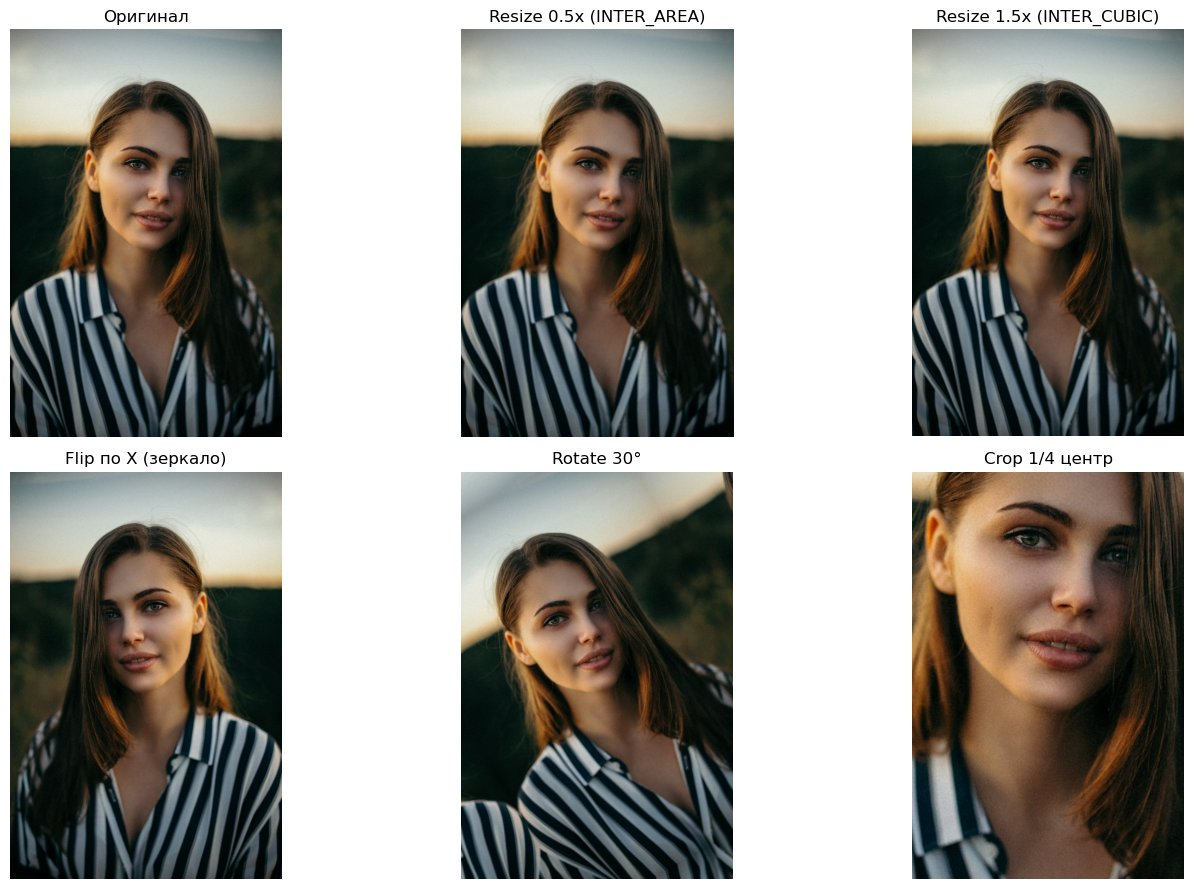

In [5]:
h, w = img_portrait.shape[:2]

# 1) Resize: уменьшаем до 50% и увеличиваем до 150%
small = cv2.resize(img_portrait, (w // 2, h // 2), interpolation=cv2.INTER_AREA)
big   = cv2.resize(img_portrait, (int(w * 1.5), int(h * 1.5)), interpolation=cv2.INTER_CUBIC)

# 2) Flip: 0 = по горизонтали, 1 = по вертикали, -1 = обе
flip_h = cv2.flip(img_portrait, 1)
flip_v = cv2.flip(img_portrait, 0)

# 3) Rotate на 30° вокруг центра
M = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0)
rotated = cv2.warpAffine(img_portrait, M, (w, h), borderMode=cv2.BORDER_REFLECT)

# 4) Crop: центральная четверть
crop = img_portrait[h // 4 : 3 * h // 4, w // 4 : 3 * w // 4]

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, im, t in zip(
    ax.flat,
    [img_portrait, small, big, flip_h, rotated, crop],
    ["Оригинал", "Resize 0.5x (INTER_AREA)", "Resize 1.5x (INTER_CUBIC)",
     "Flip по X (зеркало)", "Rotate 30°", "Crop 1/4 центр"]
):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    a.set_title(t)
    a.axis('off')
plt.tight_layout()
plt.show()


---
## 🌫️ Фильтрация (свертки)

Любой фильтр — это свёртка `dst(y,x) = Σ kernel(i,j) · src(y-i, x-j)`. Ядро определяет, что именно мы усиливаем или подавляем.

**Зачем фильтровать.** Реальные фото содержат шум от матрицы камеры, JPEG-артефакты, мелкую текстуру, которая мешает детекторам. Хорошая предобработка часто повышает точность распознавания на 5–15%. Но перефильтрация «съедает» полезные границы — нужна золотая середина.

**Gaussian blur** (`cv2.GaussianBlur(img, (k,k), sigma)`) — ядро с весами по гауссу. Сглаживает **плавный** шум (термический, низкочастотный), но слегка размывает границы. Используется почти всегда перед Canny, потому что Canny чувствителен к высокочастотному шуму.

**Median blur** (`cv2.medianBlur(img, k)`) — заменяет каждый пиксель на **медиану** по окрестности. Лучший выбор против **salt-and-pepper шума** (резкие чёрно-белые точки от битых пикселей матрицы). Сохраняет границы лучше, чем гаусс, но работает медленнее.

**Bilateral filter** (`cv2.bilateralFilter(img, d, sigmaColor, sigmaSpace)`) — гаусс по пространству + гаусс по разнице яркости. Получается «размывание фона с сохранением границ»: полезно для портретов (размытие кожи, но чёткие глаза и контур лица). Лежит в основе фильтра «красота» в смартфонах.

Правило выбора: **шум плавный → Gauss, импульсный → median, нужно сохранить контуры → bilateral.**


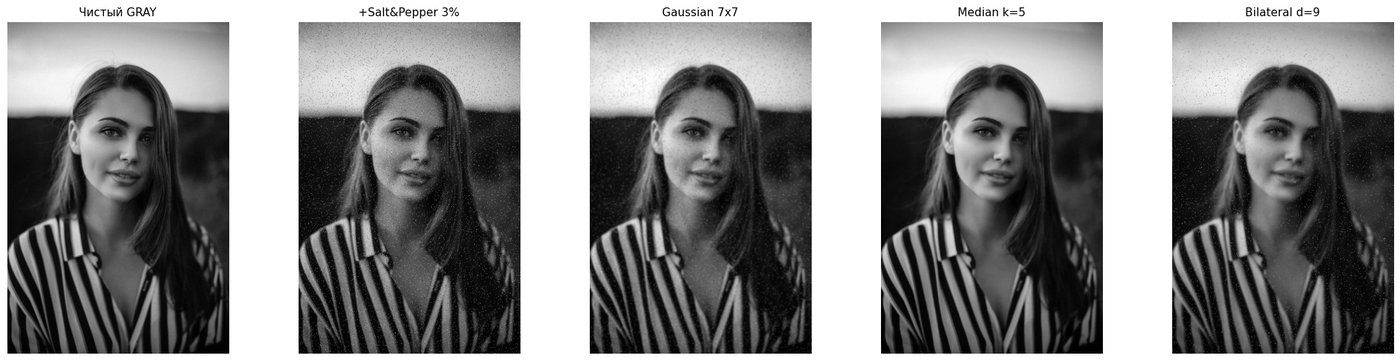

💡 Заметьте: median лучше всего убирает 'битые' пиксели, bilateral сохраняет ресницы.


In [6]:
# Возьмём серую версию и добавим искусственный salt-and-pepper, чтобы видеть разницу
gray = cv2.cvtColor(img_portrait, cv2.COLOR_BGR2GRAY)
noisy = gray.copy()
# Случайные чёрно-белые точки (3% пикселей)
rng = np.random.default_rng(42)
mask = rng.random(gray.shape) < 0.03
noisy[mask] = np.where(rng.random(gray.shape)[mask] > 0.5, 0, 255)

gauss   = cv2.GaussianBlur(noisy, (7, 7), 0)
median  = cv2.medianBlur(noisy, 5)
bilateral = cv2.bilateralFilter(noisy, d=9, sigmaColor=75, sigmaSpace=75)

fig, ax = plt.subplots(1, 5, figsize=(20, 5))
for a, im, t in zip(
    ax,
    [gray, noisy, gauss, median, bilateral],
    ["Чистый GRAY", "+Salt&Pepper 3%",
     "Gaussian 7x7", "Median k=5", "Bilateral d=9"]
):
    a.imshow(im, cmap='gray')
    a.set_title(t, fontsize=11)
    a.axis('off')
plt.tight_layout()
plt.show()
print("💡 Заметьте: median лучше всего убирает 'битые' пиксели, bilateral сохраняет ресницы.")


---
## 🧱 Морфологические операции

Морфология работает с **бинарными** (или почти бинарными) изображениями и оперирует формой. Опирается на «ядро» (structuring element) — маленькую матрицу (например, 5×5 единиц).

- **Erosion (эрозия)** — каждый пиксель становится чёрным, если хотя бы один сосед под ядром чёрный. Уменьшает белые области, «съедает» тонкие перемычки и шум.
- **Dilation (расширение)** — обратное: пиксель становится белым, если под ядром есть хотя бы один белый. Увеличивает объекты, заполняет мелкие дыры.

Комбинации:
- **Opening = erosion → dilation** — убирает мелкий белый шум, не трогая крупные объекты.
- **Closing = dilation → erosion** — заполняет мелкие чёрные дыры внутри белых объектов, соединяет близкие фрагменты.

Где применяется: очистка масок после `inRange`, подготовка бинарного изображения перед `findContours`, удаление пыли с рентгена, склейка разорванных символов в OCR.


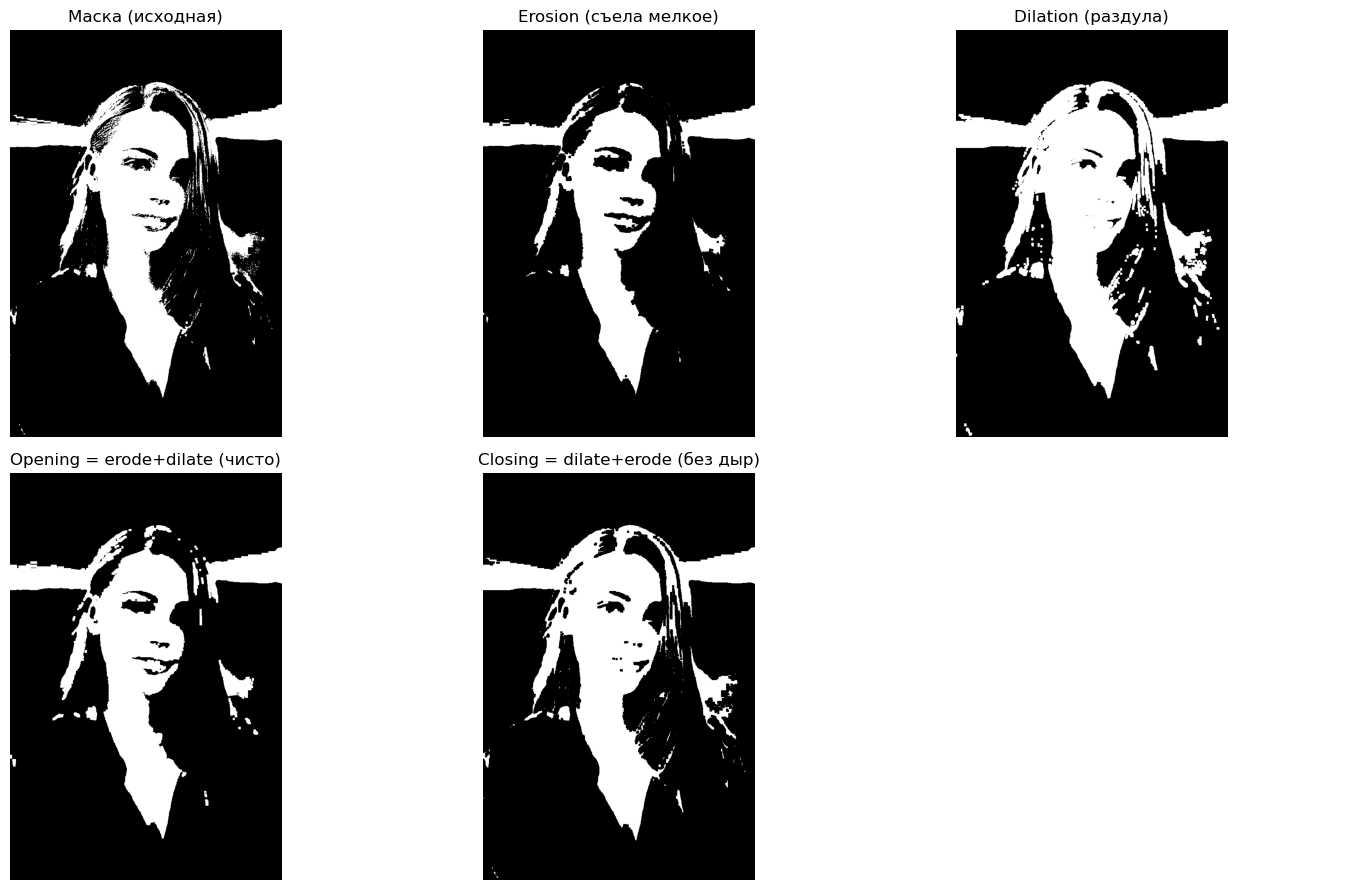

In [7]:
# Возьмём маску кожи из раздела HSV, она обычно шумная — посмотрим, как морфология её чистит
hsv = cv2.cvtColor(img_portrait, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv, (0, 30, 60), (25, 170, 255))
# Бинаризация по умолчанию уже 0/255

kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(mask, kernel, iterations=1)
dilation = cv2.dilate(mask, kernel, iterations=1)
opening = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, im, t in zip(
    ax.flat,
    [mask, erosion, dilation, opening, closing, None],
    ["Маска (исходная)", "Erosion (съела мелкое)",
     "Dilation (раздула)", "Opening = erode+dilate (чисто)",
     "Closing = dilate+erode (без дыр)", ""]
):
    if im is None:
        a.axis('off')
        continue
    a.imshow(im, cmap='gray')
    a.set_title(t)
    a.axis('off')
plt.tight_layout()
plt.show()


---
## 🪜 Детекция границ: Canny

**Граница (edge)** — это место, где яркость резко меняется. Самый известный и «умный» детектор — **Canny Edge Detector** (John Canny, 1986). Это не один оператор, а конвейер из 5 шагов:

1. **Размытие Гаусса** — подавить высокочастотный шум (иначе он сам станет «границей»).
2. **Собель (Sobel)** — вычисляем градиенты яркости $G_x$, $G_y$, отсюда модуль $G=\sqrt{G_x^2+G_y^2}$ и направление $\theta=\arctan(G_y/G_x)$.
3. **Non-maximum suppression** — утоньшение: из всех пикселей с большим градиентом в одном направлении оставляем только самый сильный. Без этого границы «жирные».
4. **Double threshold** — два порога $T_{high}, T_{low}$: пиксели > $T_{high}$ — точно граница, < $T_{low}$ — точно шум, между — кандидаты.
5. **Hysteresis (гистерезис)** — кандидат становится границей, только если соединён с уверенной границей по цепочке.

Почему не просто Sobel? Sobel даёт «жирные» градиентные карты с шумом; Canny — тонкие (1px) связные линии. В OpenCV: `cv2.Canny(img, T_low, T_high)`. Типичные значения порогов: 50/150, 100/200. Меньше пороги → больше границ (и больше шума).


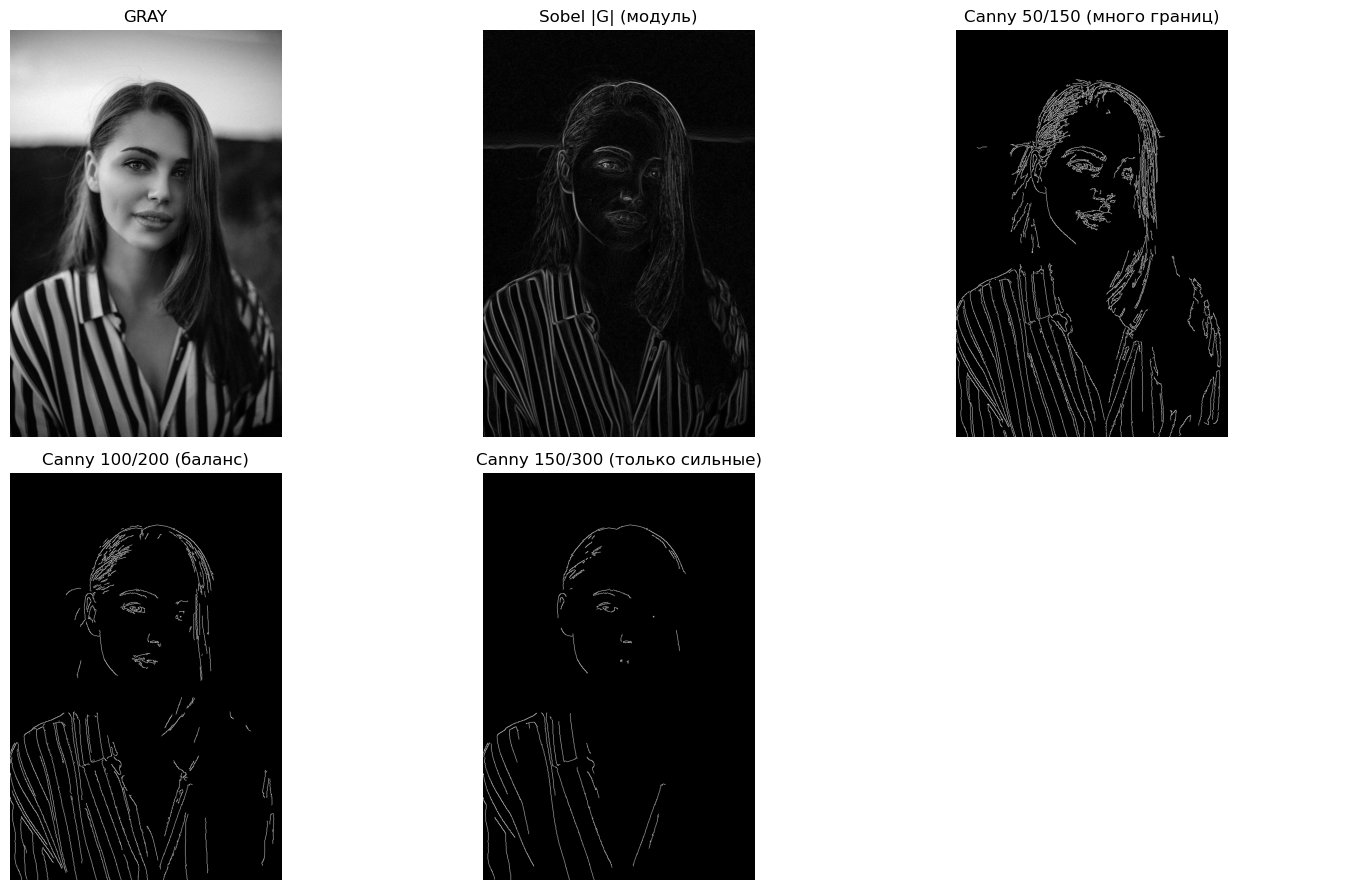

In [8]:
gray = cv2.cvtColor(img_portrait, cv2.COLOR_BGR2GRAY)

# Sobel: градиенты по X и Y, потом модуль
gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = np.sqrt(gx ** 2 + gy ** 2)
sobel_mag = (sobel_mag / sobel_mag.max() * 255).astype(np.uint8)

# Canny с тремя парами порогов
c1 = cv2.Canny(gray, 50, 150)
c2 = cv2.Canny(gray, 100, 200)
c3 = cv2.Canny(gray, 150, 300)

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, im, t in zip(
    ax.flat,
    [gray, sobel_mag, c1, c2, c3, None],
    ["GRAY", "Sobel |G| (модуль)",
     "Canny 50/150 (много границ)", "Canny 100/200 (баланс)", "Canny 150/300 (только сильные)", ""]
):
    if im is None:
        a.axis('off'); continue
    a.imshow(im, cmap='gray')
    a.set_title(t)
    a.axis('off')
plt.tight_layout()
plt.show()


---
## 🧭 Контуры: findContours

После детекции границ логично спросить: «сколько объектов на картинке и где каждый?» Для этого служит `cv2.findContours` — алгоритм Suzuki-Abe (1985) проходит бинарное изображение и выделяет связные кривые пикселей.

**Ключевые API:**
- `contours, hierarchy = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)` — `RETR_EXTERNAL` берёт только внешние контуры (без дырок), `RETR_TREE` — иерархию, `CHAIN_APPROX_SIMPLE` сжимает прямые отрезки в 2 точки (экономия памяти).
- `cv2.drawContours(img, contours, -1, (0,255,0), 2)` — нарисовать все; чтобы один — индекс.
- `M = cv2.moments(cnt)` → по моментам считаем площадь `M['m00']`, центр `(M['m10']/M['m00'], M['m01']/M['m00'])`.
- `x, y, w, h = cv2.boundingRect(cnt)` — описанный прямоугольник.
- `area = cv2.contourArea(cnt)`, `peri = cv2.arcLength(cnt, True)`.
- `approx = cv2.approxPolyDP(cnt, eps, True)` — упрощение формы: при правильном `eps` изогнутый контур превращается в 3/4/5 точек → можно отличить круг, треугольник, квадрат.

**Типичный сценарий:** бинаризация → морфология → findContours → фильтр по площади (отбрасываем шум) → boundingRect / approx → класс.


Найдено контуров: 5


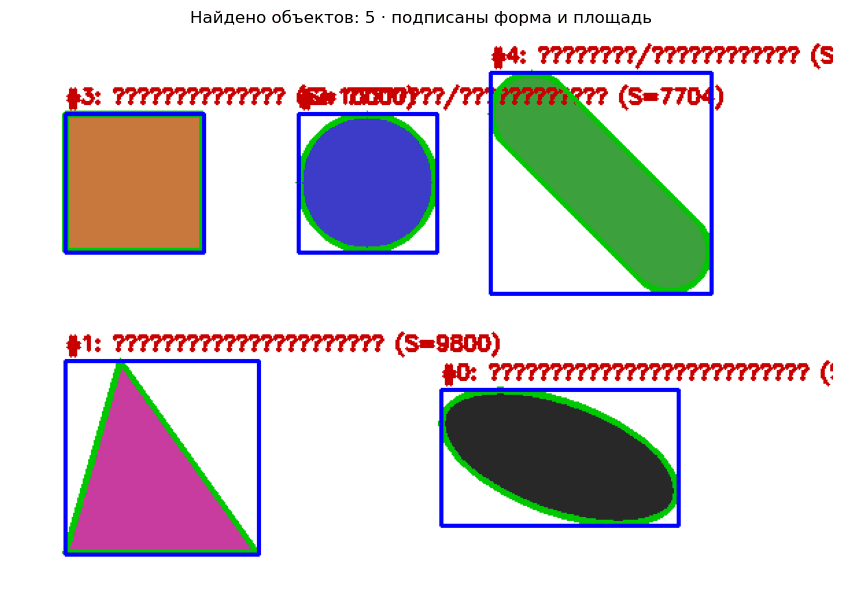

In [9]:
# Сгенерируем синтетическую сцену: 5 фигур разной формы на белом фоне
# Это удобный полигон для демонстрации контуров и классификации по форме.
scene = np.ones((400, 600, 3), dtype=np.uint8) * 255
cv2.rectangle(scene, (40, 60), (140, 160), (60, 120, 200), -1)       # квадрат
cv2.circle(scene,    (260, 110), 50, (200, 60, 60), -1)              # круг
cv2.line(scene, (380, 60), (480, 160), (60, 160, 60), 60)            # ≈ прямоугольник
triangle = np.array([[80, 240], [180, 380], [40, 380]], dtype=np.int32)
cv2.fillPoly(scene, [triangle], (160, 60, 200))                      # треугольник
cv2.ellipse(scene, (400, 310), (90, 40), 20, 0, 360, (40, 40, 40), -1)  # эллипс

gray = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, 250, 255, cv2.THRESH_BINARY_INV)

contours, hierarchy = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(f"Найдено контуров: {len(contours)}")

scene_marked = scene.copy()
for i, cnt in enumerate(contours):
    area = cv2.contourArea(cnt)
    if area < 200:        # фильтр шума
        continue
    x, y, w, h = cv2.boundingRect(cnt)
    peri = cv2.arcLength(cnt, True)
    approx = cv2.approxPolyDP(cnt, 0.04 * peri, True)
    n_vertices = len(approx)
    if n_vertices == 3:
        shape = "треугольник"
    elif n_vertices == 4:
        ar = w / float(h)
        shape = "квадрат" if 0.9 <= ar <= 1.1 else "прямоугольник"
    elif n_vertices >= 6:
        shape = "круг/эллипс"
    else:
        shape = f"{n_vertices}-угол"
    cv2.drawContours(scene_marked, [cnt], -1, (0, 200, 0), 3)
    cv2.rectangle(scene_marked, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.putText(scene_marked, f"#{i}: {shape} (S={int(area)})",
                (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 200), 2)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(scene_marked, cv2.COLOR_BGR2RGB))
plt.title(f"Найдено объектов: {len(contours)} · подписаны форма и площадь")
plt.axis('off')
plt.tight_layout()
plt.show()


---
## 🧒 Haar Cascade для детекции лиц

**Haar Cascade** — это классический метод поиска объекта (чаще всего лица) на изображении, опубликованный Виолой и Джонсом в 2001 году. Долгое время он был единственным способом实时-детекции лиц на веб-камере (30 fps на CPU Pentium III).

**Как работает.** Признаки — прямоугольные «Haar-features»: разница суммы яркостей в двух смежных прямоугольниках (например, «глаза обычно темнее щёк» —-feature «две горизонтальные полосы»). Чтобы считать сумму по прямоугольнику за O(1), используется **интегральное изображение** (summed-area table). На одном окне 24×24 существует ~160 000 таких признаков — слишком много. Поэтому AdaBoost отбирает ~6000 самых информативных и строит **каскад** из ~20–30 стадий: каждая следующая стадия проверяет только то, что прошло предыдущую. Отсюда и название *cascade* — большинство окон отбрасываются уже на 1-2 стадии, что и даёт скорость.

**В OpenCV.** Готовые каскады лежат в `cv2.data.haarcascades`: `haarcascade_frontalface_default.xml`, `haarcascade_eye.xml`, `haarcascade_fullbody.xml` и т. д. Классификатор — `cv2.CascadeClassifier(path)`, детекция — `.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=...)` → возвращает список `(x, y, w, h)`.

**Ограничения.** Haar Cascade обучался только на **анфас** лицах; профильные, повёрнутые и накрытые маской лица он пропускает. Чувствителен к освещению (резкие тени дают ложные срабатывания) и к позе. `scaleFactor > 1.1` управляет «шагом масштаба» (меньше → тщательнее, медленнее), `minNeighbors` — сколько соседних детекций нужно для подтверждения (больше → строже, меньше ложных).

**Современные альтернативы.** HOG+SVM (Dlib) — лучше с поворотом; MTCNN — нейросетевой, находит ещё и 5 ключевых точек; **YOLO** / SSD — единый детектор для всех объектов; **RetinaFace** — состояние искусства для лиц. Но Haar остаётся «hello world» CV: учит чувствовать, что такое предобработка и почему важна инвариантность.


✅ Каскад загружен: True
👤 Найдено лиц на портрете: 1


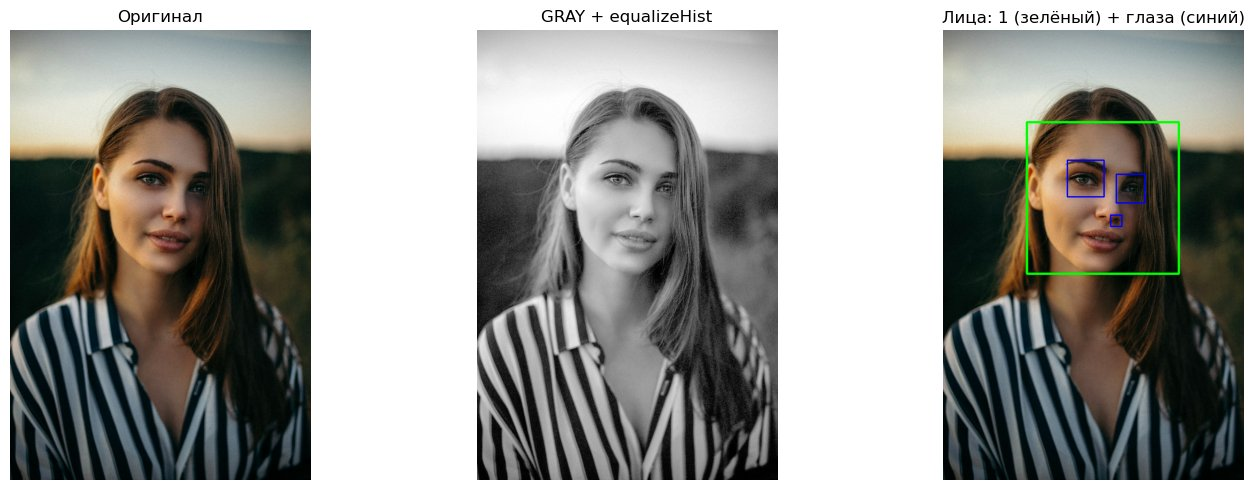

In [10]:
# Проверка, что cv2.CascadeClassifier доступен (если нет — см. инструкции выше)
if not hasattr(cv2, 'CascadeClassifier'):
    raise ImportError('cv2.CascadeClassifier не найден. Перезапустите ядро: Kernel → Restart, затем запустите ячейки сначала.')

# Загружаем предобученный каскад (идёт в комплекте с OpenCV)
cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
face_cascade = cv2.CascadeClassifier(cascade_path)
print("✅ Каскад загружен:", not face_cascade.empty())

# Обрабатываем портрет
gray = cv2.cvtColor(img_portrait, cv2.COLOR_BGR2GRAY)
gray_eq = cv2.equalizeHist(gray)   # эквализацией гистограммы подсветим черты лица

faces = face_cascade.detectMultiScale(
    gray_eq, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60)
)
print(f"👤 Найдено лиц на портрете: {len(faces)}")

marked = img_portrait.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(marked, (x, y), (x + w, y + h), (0, 255, 0), 3)

# Дополнительно: ищем глаза внутри каждого лица
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_eye.xml')
for (x, y, w, h) in faces:
    roi_gray = gray_eq[y:y + h, x:x + w]
    eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=8, minSize=(20, 20))
    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(marked, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 0, 0), 2)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(cv2.cvtColor(img_portrait, cv2.COLOR_BGR2RGB))
ax[0].set_title("Оригинал")
ax[1].imshow(gray_eq, cmap='gray')
ax[1].set_title("GRAY + equalizeHist")
ax[2].imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
ax[2].set_title(f"Лица: {len(faces)} (зелёный) + глаза (синий)")
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()


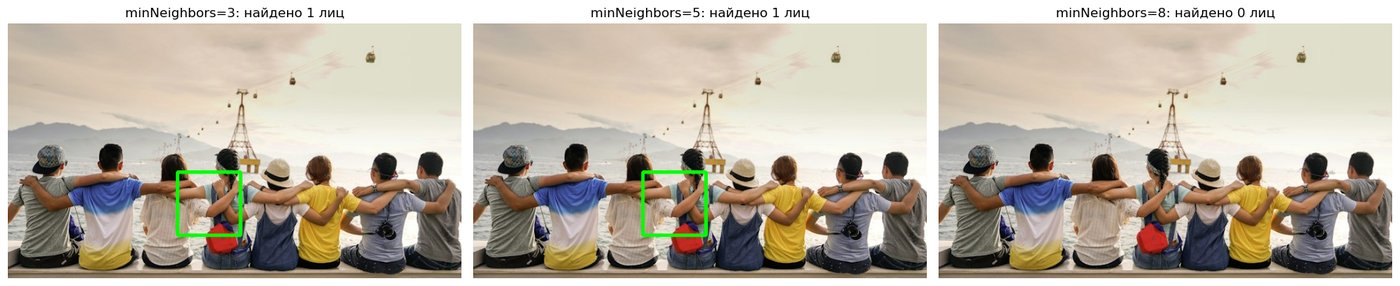

💡 Вывод: меньше minNeighbors → больше детекций, но среди них могут быть ложные.
   Больше minNeighbors → строже, но можно пропустить размытые лица.


In [11]:
# Тот же каскад — на групповом фото (несколько лиц разного размера)
gray_f = cv2.cvtColor(img_friends, cv2.COLOR_BGR2GRAY)
gray_f_eq = cv2.equalizeHist(gray_f)

# Прогоним с разными minNeighbors и сравним
results = {}
for mn in [3, 5, 8]:
    results[mn] = face_cascade.detectMultiScale(
        gray_f_eq, scaleFactor=1.1, minNeighbors=mn, minSize=(40, 40)
    )

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, (mn, fcs) in zip(ax, results.items()):
    img_copy = img_friends.copy()
    for (x, y, w, h) in fcs:
        cv2.rectangle(img_copy, (x, y), (x + w, y + h), (0, 255, 0), 3)
    a.imshow(cv2.cvtColor(img_copy, cv2.COLOR_BGR2RGB))
    a.set_title(f"minNeighbors={mn}: найдено {len(fcs)} лиц")
    a.axis('off')
plt.tight_layout()
plt.show()

print("💡 Вывод: меньше minNeighbors → больше детекций, но среди них могут быть ложные.")
print("   Больше minNeighbors → строже, но можно пропустить размытые лица.")


---
## ⭕ Подсчёт объектов: HoughCircles

**Преобразование Хафа (Hough Transform)** для окружностей перебирает все возможные центры и радиусы, голосуя в аккумулятор. Пиковые ячейки аккумулятора — наиболее вероятные окружности. Это простой, но показательный способ «посчитать монеты в кадре».

`cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=..., param1=..., param2=..., minRadius=..., maxRadius=...)`:
- `dp` — обратный масштаб аккумулятора (1 = совпадает с изображением).
- `minDist` — минимальное расстояние между центрами разных окружностей.
- `param1` — верхний порог Canny (внутренний).
- `param2` — порог голосования в аккумуляторе (меньше → больше окружностей найдётся, в т. ч. ложных).
- `minRadius / maxRadius` — ограничение по радиусу.

Демонстрация ниже генерирует синтетический кадр с монетами разных размеров на фоне, чтобы алгоритм был детерминированным и легко считался.


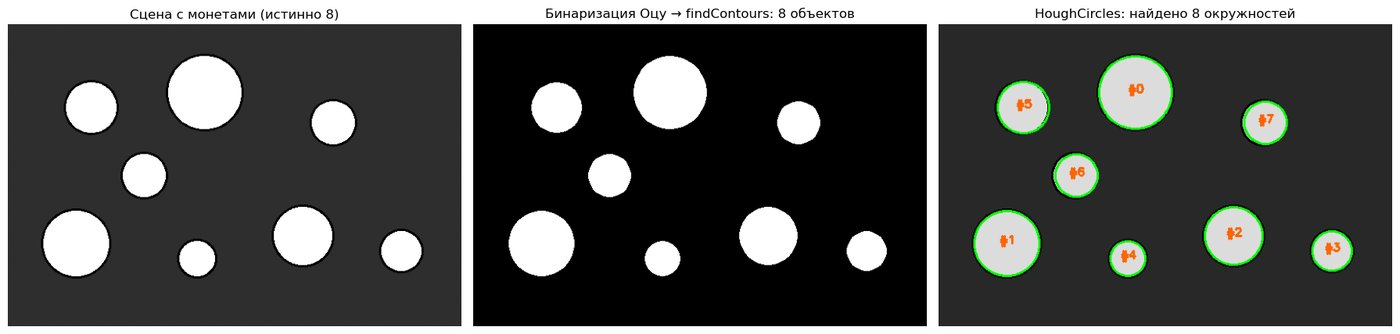

🎯 Ground truth: 8 монет
   findContours (по площади >200): 8
   HoughCircles: 8


In [12]:
# Синтетическая сцена: «монеты» (круги) на тёмном фоне. Так мы точно знаем число объектов.
coins = np.full((400, 600), 40, dtype=np.uint8)   # серый фон
# Раскладываем 8 монет разного радиуса
coins_data = [
    (110, 110, 35), (260, 90, 50), (430, 130, 30),
    (90, 290, 45), (250, 310, 25), (390, 280, 40),
    (520, 300, 28), (180, 200, 30),
]
for (cx, cy, r) in coins_data:
    cv2.circle(coins, (cx, cy), r, 220, -1)
    cv2.circle(coins, (cx, cy), r, 0, 2)

# Лёгкое размытие + бинаризация по Оцу
blur = cv2.GaussianBlur(coins, (7, 7), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 1) findContours — считаем связанные компоненты
contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
big_cnts = [c for c in contours if cv2.contourArea(c) > 200]

# 2) HoughCircles — альтернатива, специально для круглых объектов
circles = cv2.HoughCircles(
    blur, cv2.HOUGH_GRADIENT, dp=1, minDist=40,
    param1=120, param2=15, minRadius=15, maxRadius=60
)
circles = [] if circles is None else np.round(circles[0]).astype(int)

coins_rgb = cv2.cvtColor(coins, cv2.COLOR_GRAY2RGB)
for i, (x, y, r) in enumerate(circles):
    cv2.circle(coins_rgb, (x, y), r, (0, 255, 0), 2)
    cv2.putText(coins_rgb, f"#{i}", (x - 10, y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 100, 0), 2)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(coins, cmap='gray')
ax[0].set_title(f"Сцена с монетами (истинно {len(coins_data)})")
ax[1].imshow(binary, cmap='gray')
ax[1].set_title(f"Бинаризация Оцу → findContours: {len(big_cnts)} объектов")
ax[2].imshow(coins_rgb)
ax[2].set_title(f"HoughCircles: найдено {len(circles)} окружностей")
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

print(f"🎯 Ground truth: {len(coins_data)} монет")
print(f"   findContours (по площади >200): {len(big_cnts)}")
print(f"   HoughCircles: {len(circles)}")


---
## 📝 Задания для самопроверки

Запишите выводы в тетрадь (или в следующей markdown-ячейке):

1. **Цветовые пространства.** Загрузите своё фото. Сделайте маску для одного цвета через `cv2.inRange` в HSV. Какой диапазон H подходит для зелёного? для жёлтого?
2. **Фильтрация.** Добавьте на фото 5 % salt-and-pepper шума. Какой фильтр (Gauss / median / bilateral) лучше всего восстанавливает перепад яркости? Объясните почему.
3. **Морфология.** Возьмите маску из п.1. Примените opening, затем closing. Какая операция убирает мелкий шум, а какая — закрывает дыры внутри объекта?
4. **Canny.** Сравните `cv2.Canny(gray, 50, 150)` и `cv2.Canny(gray, 150, 300)`. Где границ больше? Где они «рваные»? Почему важен гистерезис (шаг 5 в алгоритме)?
5. **Контуры.** Сгенерируйте сцену с 3 кругами и 3 квадратами. Используя `approxPolyDP` + число вершин, автоматически подпишите каждый объект как «круг» / «квадрат».
6. **Haar Cascade.** Запустите детектор лиц на `real_photo_friends.jpg` для `minNeighbors = 3, 5, 8`. Сравните число детекций и количество ложных срабатываний. Объясните, почему Haar Cascade ошибается на повёрнутых лицах.
7. **HoughCircles.** Подберите `param2` так, чтобы на synthetic-сцене число найденных окружностей совпало с ground truth. Что произойдёт, если уменьшить `minDist` до 10?
8. **Главный вывод:** запишите, почему классические методы чувствительны к освещению, повороту и фону, и в каких задачах их всё равно выгодно применять (быстро, без GPU, без обучающей выборки).


---
## 🏁 Итоги практики

Вы прошли **полный классический конвейер компьютерного зрения**:

- научились **загружать** изображения в OpenCV (в т. ч. из base64) и правильно **отображать** через matplotlib, помня про BGR↔RGB;
- освоили **цветовые пространства** BGR / RGB / GRAY / HSV / LAB и поняли, когда какое применять;
- использовали **геометрические преобразования** (resize, flip, rotate, crop) и **фильтры** (Gauss, median, bilateral), разобравшись, какой фильтр от какого шума спасает;
- применили **морфологию** для чистки масок и **детектор Canny** для выделения границ, увидев, как пороги и гистерезис влияют на результат;
- научились искать **контуры** (`findContours`, `boundingRect`, `approxPolyDP`) и классифицировать форму объекта по числу вершин;
- запустили **Haar Cascade** для лиц и глаз на двух фото и поняли ограничения метода;
- посчитали **круглые объекты** через `HoughCircles`.

**Что попробовать дополнительно:**
- натренировать собственный каскад на монетах / автомобильных номерах через `opencv_createsamples` + `opencv_traincascade`;
- заменить Haar на HOG+SVM из Dlib и сравнить устойчивость к повороту;
- поиграть с оптическим потоком `cv2.calcOpticalFlowFarneback` на видео;
- подключить модуль `cv2.dnn` и запустить предобученную YOLO — это уже мостик к нейросетевой практике.

Когда классика понятна — легче осознать, какие именно признаки учится извлекать сверточная нейросеть, и почему один свёрточный слой часто «открывает» фильтры, похожие на Sobel или Haar.
